In [85]:
!pip install ucimlrepo


'pip' is not recognized as an internal or external command,
operable program or batch file.


In [86]:
from ucimlrepo import fetch_ucirepo
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [87]:
# Download dataset
bank_marketing = fetch_ucirepo(id=222)
 
# Get features and target
X = bank_marketing.data.features
y = bank_marketing.data.targets
 
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [88]:
print("First 5 rows:")
display(X.head())

# Dataset dimensions
print("Dataset Shape:", X.shape)

First 5 rows:


,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN


Dataset Shape: (45211, 16)


In [89]:
# Information about columns
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 16 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   age          45211 non-null  int64
 1   job          44923 non-null  str  
 2   marital      45211 non-null  str  
 3   education    43354 non-null  str  
 4   default      45211 non-null  str  
 5   balance      45211 non-null  int64
 6   housing      45211 non-null  str  
 7   loan         45211 non-null  str  
 8   contact      32191 non-null  str  
 9   day_of_week  45211 non-null  int64
 10  month        45211 non-null  str  
 11  duration     45211 non-null  int64
 12  campaign     45211 non-null  int64
 13  pdays        45211 non-null  int64
 14  previous     45211 non-null  int64
 15  poutcome     8252 non-null   str  
dtypes: int64(7), str(9)
memory usage: 5.5 MB


In [90]:
# Dataset description
display(X.describe())

,age,balance,day_of_week,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [92]:
missing_count = X.isnull().sum()
missing_percentage = (missing_count / len(X)) * 100

missing_report = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": missing_percentage
})

display(missing_report[missing_report["Missing Count"] > 0])

,Missing Count,Missing Percentage
job,288,0.637013
education,1857,4.107407
contact,13020,28.798301
poutcome,36959,81.747805


In [62]:
categorical_all = df.select_dtypes(include=["object", "str"]).columns

unknown_report = {}

for col in categorical_all:
    count = df[col].astype("string").str.lower().eq("unknown").sum()
    if count > 0:
        unknown_report[col] = int(count)

if unknown_report:
    display(pd.DataFrame.from_dict(
        unknown_report, orient="index", columns=["Unknown Count"]
    ))
else:
    print("No literal 'unknown' values found.")

No literal 'unknown' values found.


In [63]:
duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)

Duplicate rows: 0


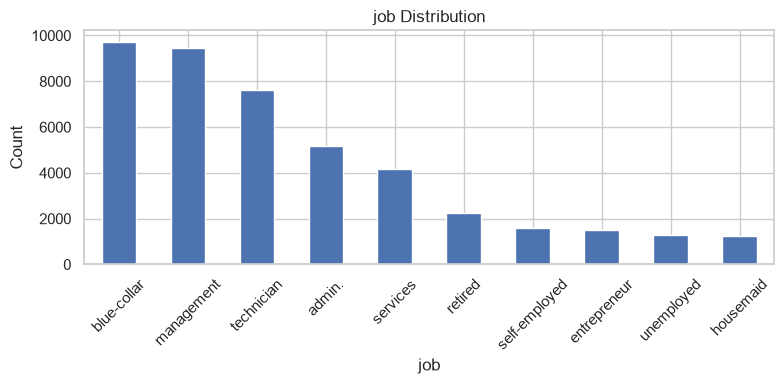

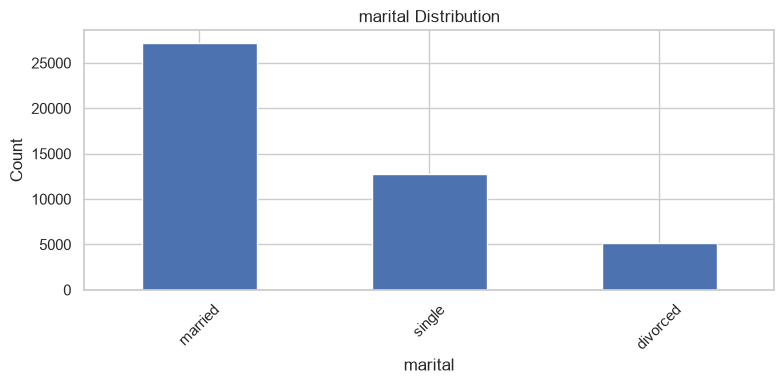

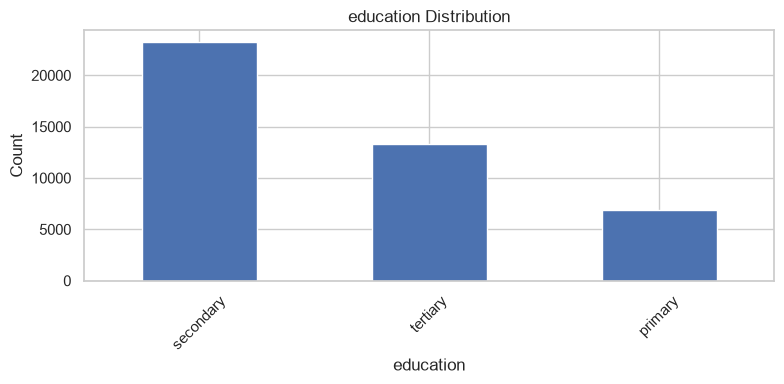

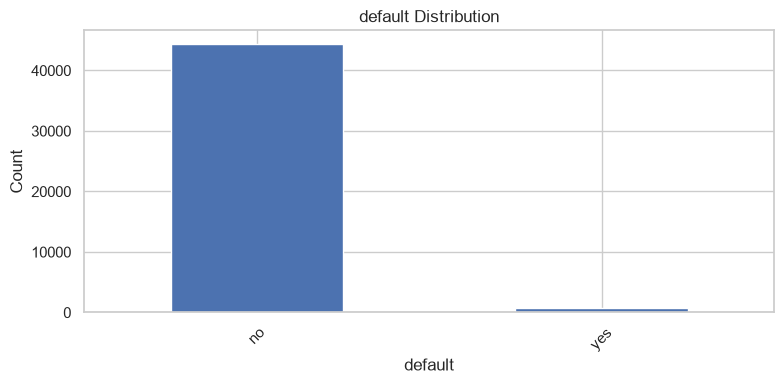

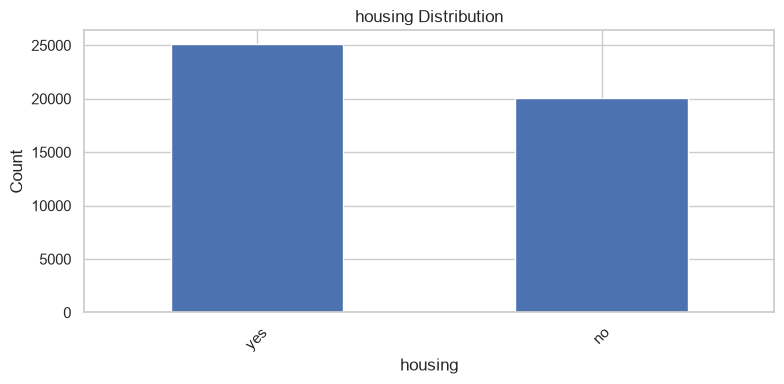

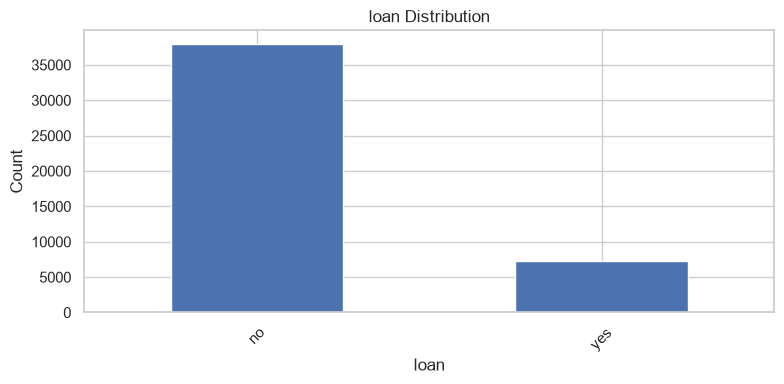

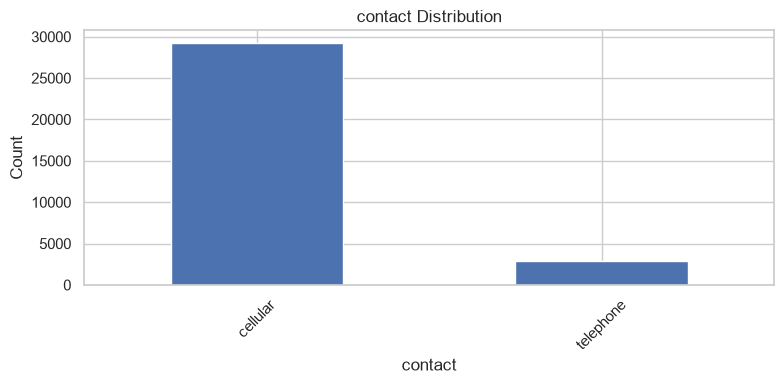

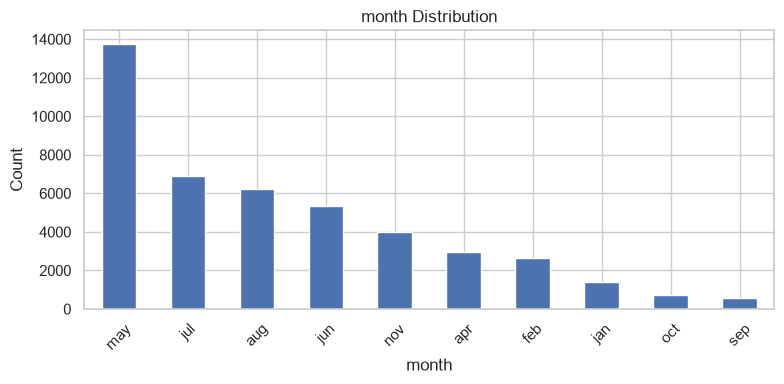

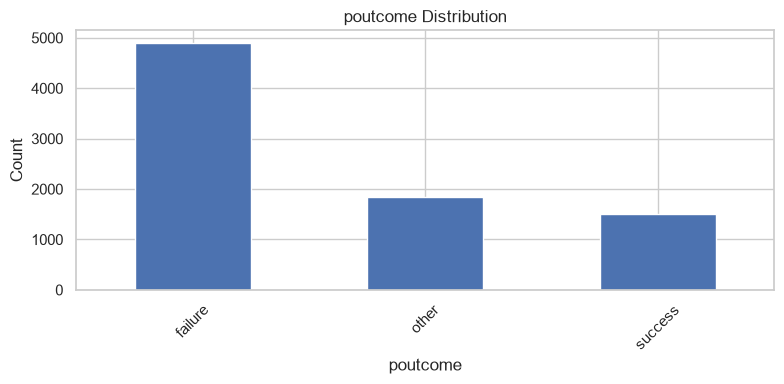

In [94]:
categorical_columns = X.select_dtypes(
    include=["object", "str"]
).columns

for column in categorical_columns:

    plt.figure(figsize=(8, 4))

    X[column].value_counts().head(10).plot(kind="bar")

    plt.title(column + " Distribution")
    plt.xlabel(column)
    plt.ylabel("Count")

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [95]:
numerical_columns = X.select_dtypes(
    include="number"
).columns

print("Numerical Columns:")
print(list(numerical_columns))

Numerical Columns:
['age', 'balance', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous']


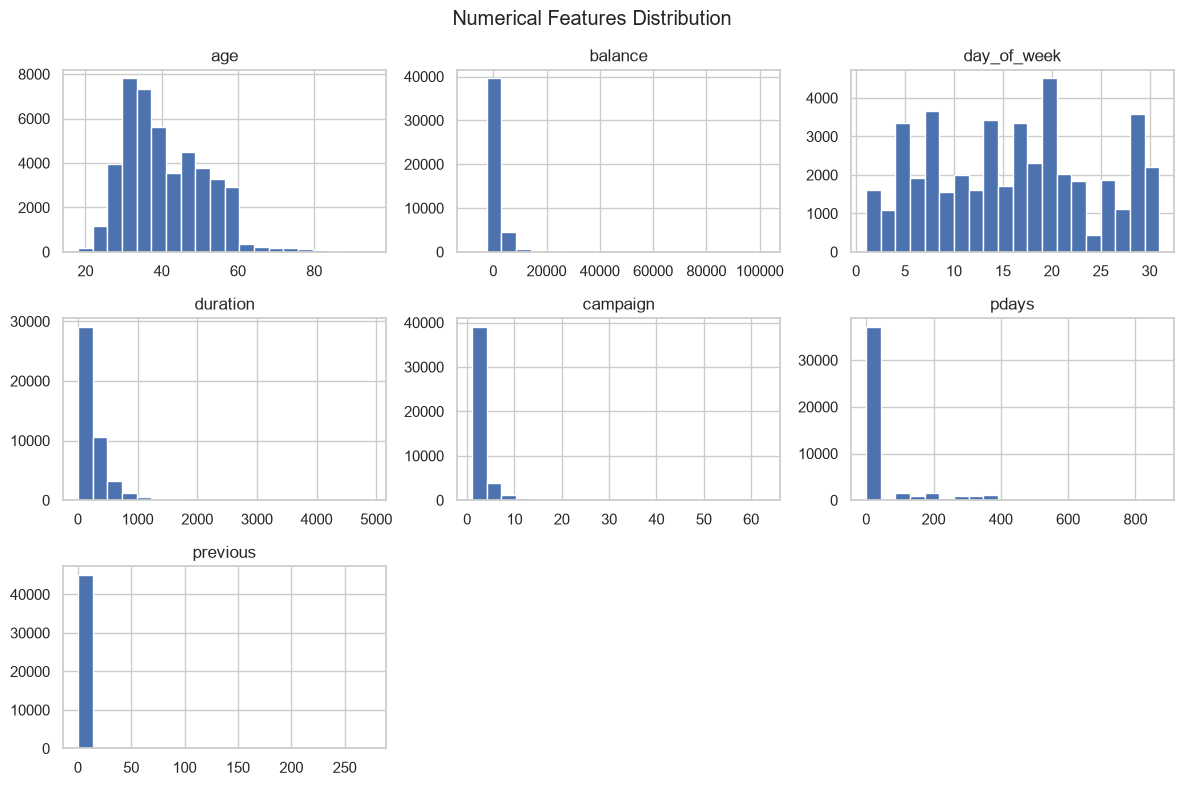

In [96]:
X[numerical_columns].hist(
    figsize=(12, 8),
    bins=20
)

plt.suptitle("Numerical Features Distribution")

plt.tight_layout()
plt.show()

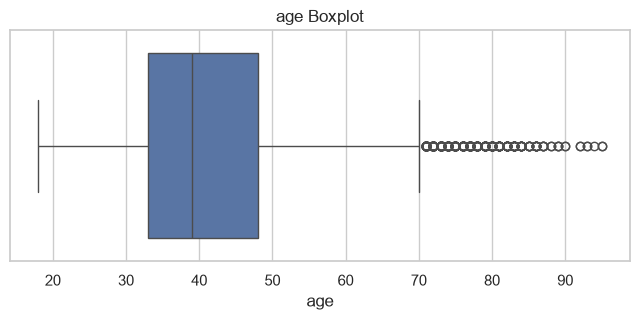

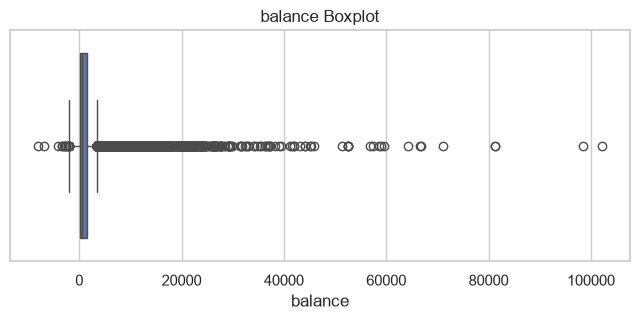

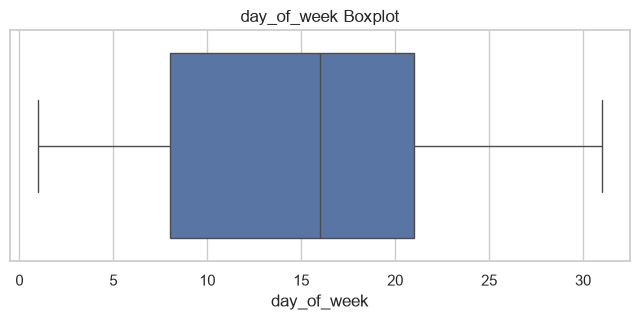

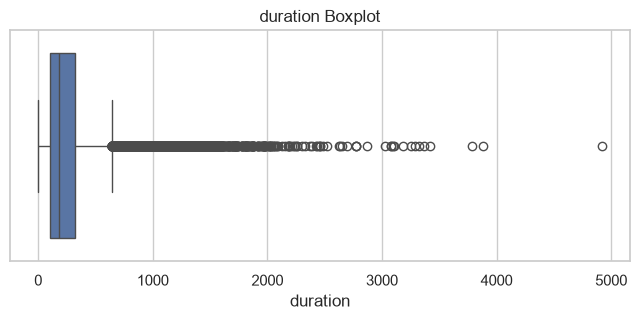

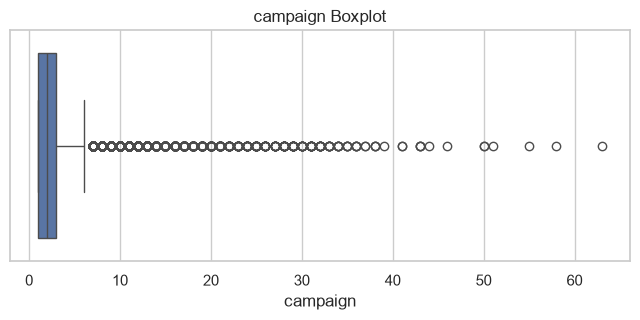

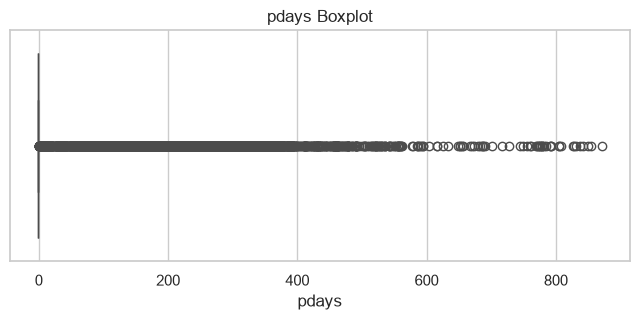

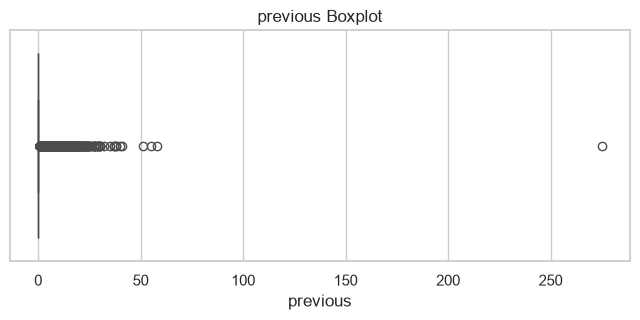

In [97]:
for column in numerical_columns:

    plt.figure(figsize=(8, 3))

    sns.boxplot(x=X[column])

    plt.title(column + " Boxplot")

    plt.show()